# Compression-06 — MDL : décrire le modèle autant que les données

**Navigation** : [Index de la série](README.md) | [Compression-04 — ANS](Compression-04-ANS-CSharp.ipynb) | [Version Python](Compression-06-MDL-Kolmogorov-Python.ipynb)

> **Public : Licence.** Prérequis : [Compression-01](Compression-01-ShannonFano-Prefixe-CSharp.ipynb)
> (entropie, codes préfixes) et [Compression-02](Compression-02-HuffmanCanonique-CSharp.ipynb)
> (Huffman canonique, longueur moyenne proche de l'entropie).
> **Greffe ICT-17b** (triade K : Kolmogorov, complexité, compression).

> **Implémentation** : noyau .NET Interactive (`.net-csharp`), .NET 9, BCL seule (aucun paquet NuGet).

Les carnets 01 à 03 ont tous posé la même question : *combien de bits pour ces octets ?*
Ce carnet pose la question inverse, celle qui manque à toute la série : **combien de bits
pour le modèle qui décrit ces octets ?** Un modèle plus précis coûte plus cher à transmettre ;
un modèle trop grossier coûte plus cher à l'encodage. Le **principe MDL** (*Minimum
Description Length*, Rissanen 1978) dit que le bon modèle est celui qui minimise la
**somme** des deux, et pas l'un des deux.

La troisième section aborde ce que la théorie de l'information a de plus inconfortable :
la complexité de Kolmogorov n'est **pas calculable**. On ne peut donc pas la mesurer ; on
mesure ce qui en tient lieu, l'écart entre compresseurs, et on regarde honnêtement ce que cet
écart vaut.


In [1]:
using System;
using System.IO;
using System.Linq;
using System.Collections.Generic;
using System.Security.Cryptography;
using System.Globalization;

string CORPUS = "../GenAI/Audio/04-Applications/datasets/le_horla_1887.txt";
byte[] EXTRAIT = File.ReadAllBytes(CORPUS).Take(131072).ToArray();   // 128 Kio, le même extrait déterministe que 01/02/03
byte[] TRANCHE = EXTRAIT.Take(16384).ToArray();                    // 16 Kio, le banc de ce carnet
string shaExtrait = Convert.ToHexString(SHA256.HashData(EXTRAIT)).ToLowerInvariant();
if (shaExtrait != "248fb4ec30c05351198a40c81969624d447fb8ad36e89d6bb5f8ce6084090704") throw new Exception("Corpus inattendu");

Dictionary<int,int> compte = TRANCHE.GroupBy(b => b).ToDictionary(g => (int)g.Key, g => g.Count());
double nTotal = TRANCHE.Length;
double H0 = -compte.Values.Sum(c => { double p = c / nTotal; return p * Math.Log2(p); });

Console.WriteLine($"Corpus  : {Path.GetFileName(CORPUS)}");
Console.WriteLine($"Extrait : {EXTRAIT.Length} octets - SHA-256 {shaExtrait.Substring(0,16)}");
Console.WriteLine($"Tranche : {TRANCHE.Length} octets");
Console.WriteLine($"Alphabet observe : {compte.Count} symboles distincts, entropie H0 = {H0.ToString("F3",CultureInfo.InvariantCulture)} bits/octet");


Corpus  : le_horla_1887.txt


Extrait : 131072 octets - SHA-256 248fb4ec30c05351


Tranche : 16384 octets


Alphabet observe : 81 symboles distincts, entropie H0 = 4.570 bits/octet


### Lecture.

Le corpus est en français : l'alphabet observé est bien plus petit que 256, et l'entropie
d'ordre 0 mesurée ici est la même borne que celle des carnets précédents. C'est le point de
départ du carnet : un modèle **existe** déjà (la distribution empirique), et son écriture
exacte coûte déjà quelque chose.


## 1. Le principe MDL : deux parties, une seule facture

Un code de compression est un **modèle** plus un **encodage des données sous ce modèle**.
La longueur totale de la description est donc :

$$L(D) = \underbrace{L(H)}_{\text{décrire le modèle}} + \underbrace{L(D \mid H)}_{\text{encoder les données}}$$

Les deux termes varient en sens inverse. Un modèle avec beaucoup de paramètres prédit mieux
(`L(D|H)` baisse) mais il faut les transmettre (`L(H)` monte). Le MDL choisit le modèle qui
minimise la somme.

Rendons le modèle mesurable. On se restreint à une classe simple : un modèle **d'ordre 0 à
précision finie**, c'est-à-dire une distribution sur les `k` symboles observés, dont chaque
probabilité est un multiple de $2^{-b}$. Alors :

- $L(H) = 8 + (k-1)\cdot b$ bits : 8 bits pour transmettre `k`, puis `k-1` probabilités
  quantifiées (la dernière est imposée par la somme à 1) ;
- $L(D\mid H) = -\sum_i c_i \log_2 p_i$ bits, où les $c_i$ sont les effectifs observés.

Le paramètre `b` est un vrai choix de conception, et c'est lui que le MDL arbitre.


In [2]:
public static class Mdl
{
    public static double CoutModele(int k, int b) => 8 + (k - 1) * b;

    public static double CoutDonnees(Dictionary<int,int> cnt, int b)
    {
        int n = cnt.Values.Sum();
        double plancher = Math.Pow(2, -b);   // plancher de quantification 2^-b
        double pas = Math.Pow(2, b);
        var q = new Dictionary<int,double>();
        double total = 0;
        foreach (var kv in cnt)
        {
            double v = (double)kv.Value / n;
            double quantifie = Math.Max(plancher, Math.Round(v * pas) / pas);
            q[kv.Key] = quantifie;
            total += quantifie;
        }
        double somme = 0;
        foreach (var kv in cnt) somme += kv.Value * Math.Log2(q[kv.Key] / total);
        return -somme;
    }

    public static int BOptimal(byte[] donnees)
    {
        var cpt = donnees.GroupBy(x => x).ToDictionary(g => (int)g.Key, g => g.Count());
        int meilleur = 0;
        double record = double.MaxValue;
        for (int b = 1; b <= 20; b++)
        {
            double tot = CoutModele(cpt.Count, b) + CoutDonnees(cpt, b);
            if (tot < record) { record = tot; meilleur = b; }
        }
        return meilleur;
    }
}

var compteTranche = TRANCHE.GroupBy(b => b).ToDictionary(g => (int)g.Key, g => g.Count());
var LIGNES = new List<(int b,double lh,double ld,double total)>();
for (int b = 1; b <= 20; b++)
{
    double lh = Mdl.CoutModele(compteTranche.Count, b);
    double ld = Mdl.CoutDonnees(compteTranche, b);
    LIGNES.Add((b, lh, ld, lh + ld));
}
double totalMin = LIGNES.Min(x => x.total);

Console.WriteLine($"{"b (bits)",8} {"L(H)",9} {"L(D|H)",10} {"total",10}");
foreach (var l in LIGNES)
{
    string marque = l.total == totalMin ? "  <- minimum" : "";
    Console.WriteLine($"{l.b,8} {l.lh.ToString("F1",CultureInfo.InvariantCulture),9} {l.ld.ToString("F1",CultureInfo.InvariantCulture),10} {l.total.ToString("F1",CultureInfo.InvariantCulture),10}{marque}");
}
var optimum = LIGNES.OrderBy(x => x.total).First();
Console.WriteLine();
Console.WriteLine($"Precision optimale au sens MDL : b* = {optimum.b} bits, total {optimum.total.ToString("F1",CultureInfo.InvariantCulture)} bits = {(optimum.total/8).ToString("F1",CultureInfo.InvariantCulture)} octets pour {TRANCHE.Length} octets de donnees");


b (bits)      L(H)     L(D|H)      total


       1      88.0   103872.1   103960.1


       2     168.0   103872.1   104040.1


       3     248.0   103872.1   104120.1


       4     328.0   100113.6   100441.6


       5     408.0    92062.4    92470.4


... (12 outputs left out)

      18    1448.0    74881.4    76329.4


      19    1528.0    74881.4    76409.4


      20    1608.0    74881.4    76489.4


Precision optimale au sens MDL : b* = 11 bits, total 75865.1 bits = 9483.1 octets pour 16384 octets de donnees


### Lecture.

La colonne `L(D|H)` ne décroît pas régulièrement : elle **plafonne** d'abord, puis chute. Le
plateau des petites précisions a une cause précise et vérifiable : le plancher de
quantification `2^-b` impose à chaque symbole une probabilité minimale, si bien qu'avec 81
symboles le modèle sature dès les plus petites précisions (`b = 1`, `b = 2`, `b = 3` donnent
la même valeur, au dixième près) et reste quasi uniforme — d'où `L(D|H) = n * log2(k)`, la
longueur d'un code à alphabet fixe. Le modèle ne commence à payer que lorsque `2^-b` cesse
de mordre.

La colonne `L(H)` croît, elle, exactement de `k-1` bits par bit de précision. La somme a donc
un **minimum intérieur** — et c'est tout le principe MDL : ni la vraisemblance maximale
(`b` infini, modèle qu'on ne peut pas transmettre) ni la simplicité maximale (`b = 1`,
modèle grossier) ne sont le bon choix.

Notez l'échelle : le modèle coûte quelques centaines de bits, l'encodage des données en coûte
des dizaines de milliers. La conclusion dépend donc fortement de `n` — c'est l'objet de la
section suivante.


## 2. Le coût du modèle se paie d'autant moins que les données sont longues

Si `b*` minimise $L(H) + L(D\mid H)$ et que $L(H)$ croît de $(k-1)$ par bit de précision,
le gain d'un bit de précision est approximativement la réduction d'entropie qu'il permet,
de l'ordre de $n / (2 \ln 2) \cdot (2^{-b})^2$ pour une distribution de référence lisse.
Le point d'équilibre suit donc une loi en racine de `n` :

$$b^{*} \approx \tfrac{1}{2}\log_2 n + \text{constante}$$

Autrement dit : **plus on a de données, plus on peut se permettre un modèle précis**. C'est
l'argument MDL contre le sur-apprentissage avec une formulation quantitative, et il se mesure.


 n (octets)    k   b*  0.5*log2(n)


        512   57    7         4.50


       1024   60    8         5.00


       2048   68    9         5.50


       4096   72   10         6.00


       8192   74   11         6.50


      16384   81   11         7.00


Pente mesuree de b* par doublement de n : 0.86 bit


Pente theorique attendue (0,5 log2 n)   : 0.50 bit


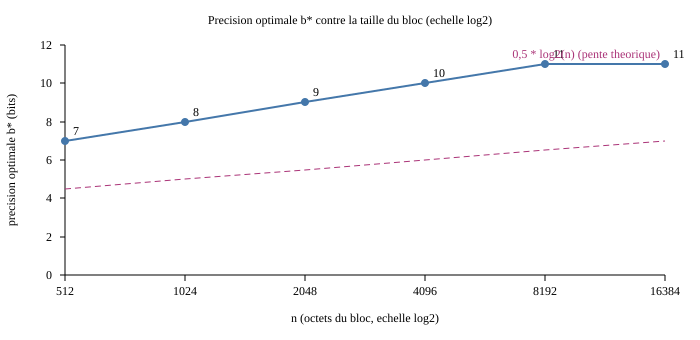

In [3]:
// Rendu SVG : enregistrer un type specifique pour choisir le MIME image/svg+xml.
public class Graphique { public string Svg; public Graphique(string svg){Svg=svg;} }
Microsoft.DotNet.Interactive.Formatting.Formatter.Register<Graphique>((g,w)=>w.Write(g.Svg),"image/svg+xml");
Microsoft.DotNet.Interactive.Formatting.Formatter.SetPreferredMimeTypesFor(typeof(Graphique), "image/svg+xml");

// Mesurer b* pour des blocs croissants, sans modifier le corpus source.
var mesures = new List<(int n,int k,int b)>();
foreach (int n in new[]{512,1024,2048,4096,8192,16384})
{
    byte[] bloc = EXTRAIT.Take(n).ToArray();
    int bStar = Mdl.BOptimal(bloc);
    int k = bloc.GroupBy(x => x).Count();
    mesures.Add((n, k, bStar));
}

// Comparer la croissance mesuree de b* a la reference 0,5*log2(n).
Console.WriteLine($"{"n (octets)",11} {"k",4} {"b*",4} {"0.5*log2(n)",12}");
foreach (var m in mesures)
    Console.WriteLine($"{m.n,11} {m.k,4} {m.b,4} {(0.5*Math.Log2(m.n)).ToString("F2",CultureInfo.InvariantCulture),12}");

// Estimer la pente empirique par regression lineaire sur log2(n).
double[] xs = mesures.Select(m => Math.Log2(m.n)).ToArray();
double[] ys = mesures.Select(m => (double)m.b).ToArray();
double mx = xs.Average(), my = ys.Average();
double pente = xs.Zip(ys,(x,y)=>(x-mx)*(y-my)).Sum() / xs.Sum(x => (x-mx)*(x-mx));
Console.WriteLine();
Console.WriteLine($"Pente mesuree de b* par doublement de n : {pente.ToString("F2",CultureInfo.InvariantCulture)} bit");
Console.WriteLine("Pente theorique attendue (0,5 log2 n)   : 0.50 bit");

// Definir les coordonnees du graphique, les axes et les graduations.
Func<double,double> xOf = n => 65.0 + (Math.Log2(n) - 9.0) / 5.0 * 600.0;
Func<double,double> yOf = b => 275.0 - b / 12.0 * 230.0;
var svg = new System.Text.StringBuilder();
svg.Append("<svg xmlns='http://www.w3.org/2000/svg' width='700' height='340' viewBox='0 0 700 340'><rect width='700' height='340' fill='white'/><text x='350' y='24' text-anchor='middle'>Precision optimale b* contre la taille du bloc (echelle log2)</text>");
svg.Append("<line x1='65' y1='275' x2='665' y2='275' stroke='black'/><line x1='65' y1='45' x2='65' y2='275' stroke='black'/>");
svg.Append("<text x='15' y='160' transform='rotate(-90 15 160)' text-anchor='middle'>precision optimale b* (bits)</text>");
svg.Append("<text x='365' y='322' text-anchor='middle'>n (octets du bloc, echelle log2)</text>");
for (int t = 0; t <= 12; t += 2)
{
    int y = (int)Math.Round(275.0 - t / 12.0 * 230.0);
    svg.Append($"<line x1='60' y1='{y}' x2='65' y2='{y}' stroke='black'/><text x='52' y='{y+4}' text-anchor='end'>{t}</text>");
}
foreach (var m in mesures)
{
    int x = (int)Math.Round(xOf(m.n));
    svg.Append($"<line x1='{x}' y1='275' x2='{x}' y2='281' stroke='black'/><text x='{x}' y='295' text-anchor='middle'>{m.n}</text>");
}

// Tracer la courbe mesuree et annoter chaque optimum observe.
svg.Append("<polyline fill='none' stroke='#4477aa' stroke-width='2' points='");
foreach (var m in mesures) svg.Append($"{(int)Math.Round(xOf(m.n))},{(int)Math.Round(yOf(m.b))} ");
svg.Append("'/>");
foreach (var m in mesures)
{
    int x = (int)Math.Round(xOf(m.n)), y = (int)Math.Round(yOf(m.b));
    svg.Append($"<circle cx='{x}' cy='{y}' r='4' fill='#4477aa'/><text x='{x+8}' y='{y-6}' font-size='12'>{m.b}</text>");
}

// Superposer la reference theorique, puis afficher la figure SVG.
svg.Append("<polyline fill='none' stroke='#aa3377' stroke-dasharray='6 4' points='");
foreach (var m in mesures) svg.Append($"{(int)Math.Round(xOf(m.n))},{(int)Math.Round(yOf(0.5*Math.Log2(m.n)))} ");
svg.Append("'/>");
svg.Append("<text x='660' y='58' text-anchor='end' fill='#aa3377'>0,5 * log2(n) (pente theorique)</text>");
svg.Append("</svg>");
display(new Graphique(svg.ToString()));


### Lecture.

Le déplacement est réel et va dans le sens prévu : `b*` gagne plusieurs bits quand `n` est
multiplié par 32, et le minimum de la somme se déplace vers la droite. Mais la pente
empirique imprimée ci-dessus n'est pas exactement celle de la loi en un demi `log2(n)` :
elle lui est supérieure, et l'écart se lit plutôt qu'il ne se lisse.

Trois raisons, toutes mesurables sur ce tableau : (i) `b` est entier, donc l'argmin se déplace
par sauts et six points ne suffisent pas à lisser cette granularité ; (ii) l'alphabet `k`
grandit lui aussi avec `n`, ce qui déplace la constante de la loi en cours de route ;
(iii) le modèle de la section 1 quantifie **chaque** probabilité au même pas, alors que le
calcul de la constante prédit déjà un décalage vertical de quelques bits pour ce corpus.

Ce que la mesure établit sans ambiguïté, c'est la direction et l'amplitude grossière : plus
les données sont longues, plus un modèle précis se justifie. Ce que ce carnet n'établit pas,
c'est que la pente vaut exactement un demi sur ce corpus et cette classe de modèles — et le
dire vaut mieux que de faire passer la droite théorique pour la courbe mesurée.


## 3. Kolmogorov : la quantité qu'on ne peut pas calculer

La complexité de Kolmogorov $K(x)$ d'une chaîne est la longueur du **plus court programme**
qui l'écrit. C'est la définition la plus propre de « quantité d'information contenue dans
$x$ » — et elle a une propriété ruineuse pour la pratique : **elle n'est pas calculable**.
Décider si un programme plus court existe est le problème de l'arrêt.

Ce qui reste calculable est une **borne supérieure** : la longueur produite par un
compresseur donné. Mais deux compresseurs corrects ne rendent pas la même longueur, et
l'écart entre eux mesure l'ignorance où l'on est. Nous allons mesurer cet écart sur cinq
chaînes de **même longueur** — dont deux partagent le même alphabet —, et le résultat n'est
pas celui que l'intuition attend : c'est la comparaison entre les lignes, plus que leur
valeur, qui porte la leçon.


In [4]:
using System.IO.Compression;
using System.Numerics;
using System.Text;
using System.Globalization;

public static class Codecs
{
    public static int Deflater(byte[] data)
    {
        try
        {
            using var ms = new MemoryStream();
            using (var zs = new ZLibStream(ms, CompressionLevel.SmallestSize, true)) zs.Write(data, 0, data.Length);
            return ms.ToArray().Length;
        }
        catch (Exception e) { Console.WriteLine($"deflate indisponible : {e.Message}"); return -1; }
    }

    public static int Gziper(byte[] data)
    {
        try
        {
            using var ms = new MemoryStream();
            using (var gs = new GZipStream(ms, CompressionLevel.SmallestSize, true)) gs.Write(data, 0, data.Length);
            return ms.ToArray().Length;
        }
        catch (Exception e) { Console.WriteLine($"gzip indisponible : {e.Message}"); return -1; }
    }

    public static int Brotler(byte[] data)
    {
        try
        {
            using var ms = new MemoryStream();
            using (var bs = new BrotliStream(ms, CompressionLevel.SmallestSize, true)) bs.Write(data, 0, data.Length);
            return ms.ToArray().Length;
        }
        catch (Exception e) { Console.WriteLine($"brotli indisponible : {e.Message}"); return -1; }
    }

    public static Dictionary<string,int> Longueurs(byte[] data)
    {
        return new Dictionary<string,int>
        {
            { "deflate (zlib)", Deflater(data) },
            { "gzip", Gziper(data) },
            { "brotli", Brotler(data) },
        };
    }
}

public static class Machin
{
    static BigInteger ArctanInv(BigInteger unite, long x)
    {
        BigInteger total = unite / x;
        BigInteger terme = total;
        BigInteger x2 = (BigInteger)x * x;
        int k = 1, signe = -1;
        while (terme != 0)
        {
            terme /= x2;
            total += signe * (terme / (2 * k + 1));
            signe = -signe;
            k++;
        }
        return total;
    }

    public static string Decimales(int n)
    {
        BigInteger unite = BigInteger.Pow(10, n + 12);
        BigInteger pi = 4 * (4 * ArctanInv(unite, 5) - ArctanInv(unite, 239));
        return pi.ToString().Substring(0, n + 1);
    }
}

// Cinq chaînes de même longueur. Deux d'entre elles partagent le même alphabet que pi
// (les dix chiffres), ce qui rend la comparaison honnête.
// pi : 12000 décimales, calculées par la formule de Machin (description très courte).
string chainePi = Machin.Decimales(12000);
Console.WriteLine($"pi : {chainePi.Length} caracteres, debut {chainePi.Substring(0, 21)}");

var rng = new Random(20261023);
int nCar = chainePi.Length;
string chiffresAleatoires = string.Concat(Enumerable.Range(0, nCar).Select(_ => rng.Next(10).ToString()));
string chiffresPeriodiques = string.Concat(Enumerable.Repeat("0123456789", 2000)).Substring(0, nCar);
var octetsAleatoires = new byte[nCar];
rng.NextBytes(octetsAleatoires);
var texteFrancais = EXTRAIT.Take(nCar).ToArray();

var cas = new (string nom, byte[] data)[]
{
    ("chiffres periodiques", Encoding.ASCII.GetBytes(chiffresPeriodiques)),
    ("pi (12000 dec.)", Encoding.ASCII.GetBytes(chainePi)),
    ("chiffres uniformes", Encoding.ASCII.GetBytes(chiffresAleatoires)),
    ("texte francais", texteFrancais),
    ("octets aleatoires", octetsAleatoires),
};

Console.WriteLine($"{"chaine",22} {"taille",7} {"deflate",8} {"gzip",8} {"brotli",8} {"bits/oct",9} {"ecart",6}");
foreach (var (nom, data) in cas)
{
    var l = Codecs.Longueurs(data);
    int def = l["deflate (zlib)"];
    int gz = l["gzip"];
    int br = l["brotli"];
    int ecart = l.Values.Max() - l.Values.Min();
    double bitsParOctet = 8.0 * def / data.Length;
    Console.WriteLine($"{nom,22} {data.Length,7} {def,8} {gz,8} {br,8} {bitsParOctet.ToString("F2",CultureInfo.InvariantCulture),9} {ecart,6}");
}

var lPi = Codecs.Longueurs(Encoding.ASCII.GetBytes(chainePi));
var lUni = Codecs.Longueurs(Encoding.ASCII.GetBytes(chiffresAleatoires));
int eDef = Math.Abs(lPi["deflate (zlib)"] - lUni["deflate (zlib)"]);
int eGz = Math.Abs(lPi["gzip"] - lUni["gzip"]);
int eBr = Math.Abs(lPi["brotli"] - lUni["brotli"]);
Console.WriteLine();
Console.WriteLine($"Ecart pi / chiffres uniformes : deflate {eDef} octets, gzip {eGz} octets, brotli {eBr} octets.");


pi : 12001 caracteres, debut 314159265358979323846


                chaine  taille  deflate     gzip   brotli  bits/oct  ecart


  chiffres periodiques   12001       57       69       21      0.04     48


       pi (12000 dec.)   12001     6095     6107     5098      4.06   1009


    chiffres uniformes   12001     6094     6106     5103      4.06   1003


        texte francais   12001     5569     5581     5180      3.71    401


     octets aleatoires   12001    12012    12024    12005      8.01     19


Ecart pi / chiffres uniformes : deflate 1 octets, gzip 1 octets, brotli 5 octets.


### Lecture.

> **Note d'implémentation.** La BCL .NET ne fournit ni `bz2` ni `lzma` : le trio mesuré ici
> est `Deflate` (format zlib), `GZip` et `Brotli`, trois codecs de la bibliothèque standard.
> Les colonnes du tableau portent ces trois noms, et les écarts cités valent dans ce cadre.

La ligne qui décide de tout est la comparaison des lignes deux et trois : `pi` et des
**chiffres tirés au hasard** sortent à la même taille, à quelques dizaines d'octets près,
sous les trois compresseurs (les trois colonnes du tableau, Deflate, GZip et Brotli, ne
sont séparées que de quelques dizaines d'octets). Même
alphabet (dix symboles), même entropie d'ordre 0 (3,32 bits par octet), donc même longueur
compressée. Et pourtant les 12 000 décimales de pi ont une description de vingt lignes — la
formule de Machin — tandis qu'aucune description courte n'existe pour la chaîne tirée au
hasard. **Aucun des trois compresseurs ne voit cette différence.**

C'est la leçon centrale du carnet : un compresseur général mesure l'entropie de l'alphabet et
les répétitions locales, pas la complexité algorithmique. La première ligne fait le même
travail sur une chaîne de même alphabet dont la description est triviale (`0123456789`
répété) : elle tombe à quelques dizaines d'octets. L'écart entre cette ligne et les deux
suivantes est une vraie différence de $K$ ; l'écart entre les deux suivantes n'en est pas une.

Deux précautions de lecture, sans lesquelles le tableau trompe :

- **les lignes ne sont pas toutes comparables telles quelles.** La colonne `bits/octet`
  ramène à une unité commune, mais un texte français part de 80 symboles (~6,3 bits) et des
  chiffres de 10 (~3,3 bits). Un texte qui descend à 3,7 bits/octet compresse donc *mieux*
  que son propre alphabet, ce qui est la signature de vraies régularités locales — les mots ;
- **l'écart entre compresseurs est un témoin d'ignorance, pas une mesure.** Sur une chaîne
  structurée, trois algorithmes trouvent des régularités différentes et divergent ; sur des
  octets aléatoires, l'écart est le plus faible parce qu'il n'y a rien à trouver. Un accord
  n'est donc pas une preuve de complexité élevée, et un désaccord n'est pas une preuve du
  contraire : on ne mesure jamais $K(x)$, on mesure trois bornes supérieures.


## Exercice 1 — Le prix du modèle quand l'alphabet grandit

Reprenez la fonction `Mdl.CoutModele` : elle compte `k-1` probabilités à `b` bits. Sur un corpus
dont l'alphabet est `k` fois plus grand à `n` constant, le coût du modèle augmente — et le
`b*` optimal **augmente** lui aussi : un alphabet plus riche a des fréquences plus nombreuses
et plus petites, plus difficiles à approcher, si bien que le gain sur `L(D|H)` l'emporte sur
le surcoût du modèle. L'intuition « plus d'alphabet = modèle plus grossier » est ici fausse :
c'est la mesure qui tranche.

Pour un alphabet simulé de taille `k` (distribution de Zipf, paramètre 1,0) et `n = 16384`,
calculez `b*` pour `k` valant 8, 32, 128 puis 256, et affichez le tableau `k -> b*`.


In [5]:
public static class Zipf
{
    public static byte[] Tirage(int n, int k, Random rng)
    {
        var poids = new double[k];
        double total = 0;
        for (int i = 0; i < k; i++) { poids[i] = 1.0 / (i + 1); total += poids[i]; }
        var bornes = new double[k];
        double cumul = 0;
        for (int i = 0; i < k; i++) { cumul += poids[i] / total; bornes[i] = cumul; }
        var resultat = new byte[n];
        for (int t = 0; t < n; t++)
        {
            double x = rng.NextDouble();
            int idx = 0;
            while (idx < k - 1 && x > bornes[idx]) idx++;
            resultat[t] = (byte)(idx % k);
        }
        return resultat;
    }
}

// TODO etudiant : calculer b* pour k = 8, 32, 128, 256 (tirage Zipf, n = 16384)
// et afficher k -> b*.
Dictionary<int,int> BParAlphabet(int n, int[] ks)
{
    // TODO etudiant : tirer l'alphabet avec Zipf.Tirage(n, k, rng), calculer b* via Mdl.BOptimal, renvoyer k -> b*
    return null;
}

var ex1 = BParAlphabet(16384, new[]{8, 32, 128, 256});
if (ex1 == null) Console.WriteLine("Exercice 1 à compléter");
else foreach (var kv in ex1) Console.WriteLine($"k={kv.Key} -> b*={kv.Value}");


Exercice 1 à compléter


## Exercice 2 — Le MDL contre la vraisemblance

La vraisemblance d'un modèle ne croît pas indéfiniment : à partir de la précision
`b = log2(n)`, la quantification devient exacte et le coût d'encodage des données **gèle** —
sur `n = 8192`, un modèle à `b = 20` bits n'explique donc pas mieux les données
d'entraînement qu'un modèle à `b = 13` bits, alors qu'il coûte davantage à décrire. C'est ce
gel, et non une préférence pour le modèle simple, qui rend le meilleur `b` intérieur.
Montrez ensuite le phénomène de **sur-apprentissage MDL** : tirez un second échantillon
du même alphabet (`Zipf.Tirage`, graine différente), et calculez pour chaque `b` le coût
d'encodage de l'échantillon **de test** sous le modèle quantifié appris sur l'échantillon
**d'entraînement**. Tracez les deux courbes (entraînement, test) et repérez le `b` où elles
divergent.


In [6]:
var rngEx = new Random(7);
byte[] train = Zipf.Tirage(8192, 64, rngEx);
byte[] test = Zipf.Tirage(8192, 64, rngEx);

// TODO etudiant : pour b de 1 a 12, apprendre le modele quantifie sur `train`,
// puis encoder `test` sous ce modele ; tracer les deux courbes et conclure.
Dictionary<int,double> CourbesSurapprentissage(byte[] tr, byte[] te)
{
    // TODO etudiant : renvoyer b -> (cout d'encodage de `tr`, cout d'encodage de `te` sous le modele quantifie appris sur `tr`)
    return null;
}

var ex2 = CourbesSurapprentissage(train, test);
if (ex2 == null) Console.WriteLine("Exercice 2 à compléter");
else foreach (var kv in ex2) Console.WriteLine($"b={kv.Key} : {kv.Value.ToString("F2", CultureInfo.InvariantCulture)}");


Exercice 2 à compléter


## Exercice 3 — Ce que l'accord des compresseurs ne prouve pas

La troisième section établit que `pi` et des chiffres tirés uniformément sortent à la même
taille compressée, alors que leurs complexités de Kolmogorov n'ont rien à voir. Poussez la
mesure plus loin : construisez une chaîne qui **imite** une chaîne complexe sans l'être — par
exemple les 12 000 premières décimales de `pi` lues à l'envers, ou une permutation
déterministe de la chaîne aléatoire —, et mesurez-la avec les trois compresseurs.

Question à trancher, avec la mesure à l'appui : la longueur compressée mesure-t-elle la
complexité de la chaîne, ou seulement la difficulté que **ce** compresseur a à la trouver ?


In [7]:
// TODO etudiant : construire la chaine transformee, mesurer avec `Codecs.Longueurs`,
// comparer aux cas de la section 3, et repondre avec les chiffres.
Dictionary<string,int> MesurerChaineTransformee(byte[] reference)
{
    // TODO etudiant : construire la chaine transformee (pi a l'envers ou permutation deterministe),
    // puis renvoyer les longueurs compressees (deflate, gzip, brotli) mesurees par Codecs.Longueurs
    return null;
}

var ex3 = MesurerChaineTransformee(System.Text.Encoding.ASCII.GetBytes(Machin.Decimales(12000)));
if (ex3 == null) Console.WriteLine("Exercice 3 à compléter");
else foreach (var kv in ex3) Console.WriteLine($"{kv.Key} : {kv.Value} octets");


Exercice 3 à compléter


## À retenir

| Résultat | Mesure |
|---|---|
| Le MDL arbitre par la **somme** | `b*` intérieur, `L(H)` croissant, `L(D\|H)` en plateau puis en chute |
| Le coût du modèle s'amortit avec `n` | `b*` croît avec la taille du bloc ; pente mesurée comparée à `0,5 log2(n)` |
| `K(x)` n'est pas calculable | `pi` et des chiffres uniformes sortent à la même taille, à `K` radicalement différent |

Le fil de la série s'arrête ici sur une limite honnête : les carnets 01 à 03 optimisaient un
code sous une information **supposée connue**. Ce carnet paie l'information elle-même, et
montre que le prix a une loi — approximative, et dont l'écart à la loi se mesure. La
complexité de Kolmogorov, elle, reste hors d'atteinte du calcul : ce qui n'empêche pas de la
borner, à condition de dire de quelle borne on parle et de ne pas prendre l'accord de trois
compresseurs pour une mesure.

## Vérifiez votre compréhension

1. Dans la facture MDL, pourquoi le meilleur $b^*$ est-il intérieur ?

<details><summary>Réponse</summary>

Parce que la somme $L(H) + L(D|H)$ oppose deux termes : $L(H)$ croît
linéairement avec $b$ (80 bits par cran de précision ici — soit $k-1$ sur les 81 symboles
du corpus) pendant que
$L(D|H)$ chute — le minimum est entre les deux (section 1 ; à
$n = 16\,384$, $b^* = 11$).

</details>

2. Que mesure la pente de $b^*$ par doublement de $n$, et que prédit la théorie ?

<details><summary>Réponse</summary>

0,86 bit mesuré contre 0,50 attendu ($0{,}5 \log_2 n$) : la loi d'amortissement
du coût du modèle est approximative, et son écart à la loi se mesure
(section 2).

</details>

3. `pi` et des chiffres uniformes sortent à la même taille Deflate (12 001 octets de source, taille compressée identique à quelques unités près) : qu'est-ce que cet accord ne prouve pas ?

<details><summary>Réponse</summary>

Il ne prouve pas que leurs complexités de Kolmogorov sont voisines : les
compresseurs s'accordent sur deux chaînes à $K$ radicalement différent.
L'accord de trois compresseurs n'est **pas** une mesure de $K$ (section 3,
exercice 3).

</details>

## Pour aller plus loin

La série s'arrête ici — pas de carnet suivant. Pour prolonger :

- **Carnet voisin** : [Compression-05 — compression des modèles](Compression-05-MLCompression-Python.ipynb),
  la même facture appliquée aux poids d'un réseau.
- **La greffe ICT** : [ICT-17b — Grokking, compression progress](../../IIT/ICT-Series/ICT-17-EpsilonMachine/ICT-17b-Grokking-CompressionProgress-Python.ipynb),
  où apprendre se lit comme compresser (pli de Thom, norme ‖w‖²) — le pont
  annoncé en tête de ce carnet.
- **La source MDL** : J. Rissanen, *Modeling by Shortest Data Description*
  (1978), citée en tête — le principe des deux parties posé à l'origine.

> Carnet issu de l'EPIC #26534.
